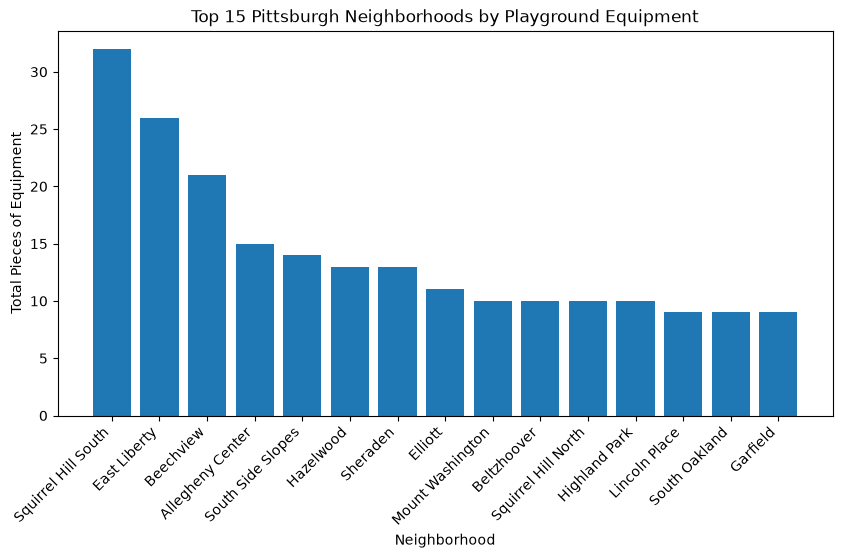

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

url = "https://data.wprdc.org/datastore/dump/e39ef76e-0a11-47c8-a86f-a37f55db7a2b"
playgrounds = pd.read_csv(url)

playgrounds.columns = playgrounds.columns.str.lower()
playgrounds = playgrounds.dropna(subset=["neighborhood"])

neighborhood_playgrounds = pd.DataFrame()
neighborhood_playgrounds["total_equipment"] = playgrounds.groupby("neighborhood")["id"].count()
neighborhood_playgrounds["unique_playgrounds"] = playgrounds.groupby("neighborhood")["name"].nunique()
neighborhood_playgrounds["equipment_diversity"] = playgrounds.groupby("neighborhood")["equipment_type"].nunique()
neighborhood_playgrounds = neighborhood_playgrounds.reset_index()

neighborhood_playgrounds = neighborhood_playgrounds.sort_values("total_equipment", ascending=False)
max_equipment = neighborhood_playgrounds["total_equipment"].max()
neighborhood_playgrounds["playground_score"] = (neighborhood_playgrounds["total_equipment"] / max_equipment) * 100

top_15 = neighborhood_playgrounds.head(15)

plt.figure(figsize=(10, 5))
plt.bar(top_15["neighborhood"], top_15["total_equipment"])
plt.title("Top 15 Pittsburgh Neighborhoods by Playground Equipment")
plt.xlabel("Neighborhood")
plt.ylabel("Total Pieces of Equipment")
plt.xticks(rotation=45, ha="right")
plt.show()

## Conclusion & Personal Reflection

Based on the playground equipment dataset, Squirrel Hill South (32 pieces of equipment across 8 playgrounds) and East Liberty (26 pieces of equipment across 3 playgrounds) ranked as the top neighborhoods in Pittsburgh since they have the highest total amount of equipment.

Looking at these results shows a few important things about how the numbers compare with real life:
- Larger residential neighborhoods with big community parks have way more playground equipment than busy commercial areas or college campuses.
- Counting total equipment favors neighborhoods with large parks, which measures how much equipment there is rather than the actual condition or quality of the playgrounds.
- Having a low playground count does not mean a neighborhood is bad or lacks outdoor space. Most of the time, it just comes down to who lives there, areas without many young families have less need for playgrounds.

### Comparison with Personal Favorite

My personal favorite neighborhood in Pittsburgh is Central Oakland.

Unlike residential areas with lots of parks like Squirrel Hill South and East Liberty, Central Oakland ranks near the bottom for this metric because it barely has any playground equipment. Since it is the center of Pitt's campus, the neighborhood is built around college students rather than young families, so the space goes toward academic buildings, dorms, apartments, and local businesses instead of playgrounds.

Even though it scored low here, Central Oakland is still my favorite neighborhood because of its convenience. You are right next to classes, food spots along Forbes and Fifth Avenues, the Cathedral of Learning, and within walking distance of Schenley Park.

This difference shows the limitation of only looking at playground data: a high equipment count shows that a neighborhood is great for families with kids, not whether it is convenient, lively, or a good fit for everyone else. While playground equipment is a helpful metric for looking at city amenities, finding the overall best neighborhood means combining this data with other factors across Pittsburgh.